In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

uploaded = files.upload()

df = pd.read_csv("cardekho_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.isnull().sum())

Saving cardekho_dataset.csv to cardekho_dataset.csv
Dataset shape: (15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


None

,0
Unnamed: 0,0
car_name,0
brand,0
model,0
vehicle_age,0
km_driven,0
seller_type,0
fuel_type,0
transmission_type,0
mileage,0


In [2]:
features = [
    'vehicle_age',
    'km_driven',
    'mileage',
    'engine',
    'max_power',
    'seats'
]

target = 'selling_price'

df = df.drop_duplicates()

df = df.dropna(
    subset=features + [target]
)

X = df[features]
y = df[target]

print("Final dataset shape:", df.shape)

Final dataset shape: (15411, 14)


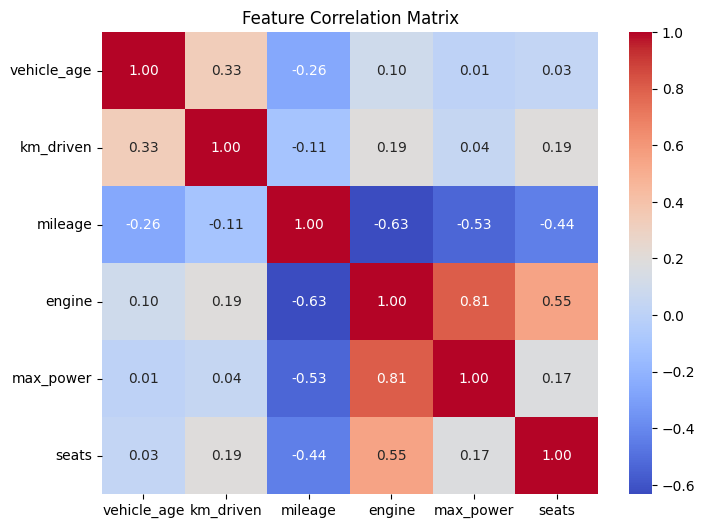

In [3]:
corr = X.corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Feature Correlation Matrix")
plt.show()

In [4]:
vif = pd.DataFrame()

vif["Feature"] = X.columns

vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

display(vif)

,Feature,VIF
0,vehicle_age,1.275961
1,km_driven,1.207432
2,mileage,1.933761
3,engine,6.232661
4,max_power,4.499991
5,seats,2.245696


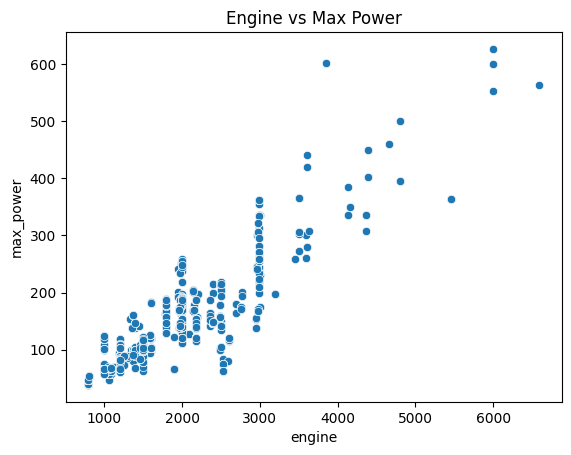

In [5]:
sns.scatterplot(
    data=df,
    x='engine',
    y='max_power'
)

plt.title("Engine vs Max Power")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

y_pred_ols = ols.predict(X_test_scaled)

ols_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_ols)
)

ols_r2 = r2_score(
    y_test,
    y_pred_ols
)

print("OLS RMSE:", ols_rmse)
print("OLS R²:", ols_r2)

OLS RMSE: 505598.95924913284
OLS R²: 0.6604191137119326


In [8]:
ols_coef = pd.DataFrame({
    'Feature': features,
    'OLS': ols.coef_
})

display(ols_coef)

,Feature,OLS
0,vehicle_age,-185582.764045
1,km_driven,-51063.343589
2,mileage,63347.133463
3,engine,52499.729361
4,max_power,665027.570237
5,seats,4599.893525


In [9]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

results = []

for alpha in alphas:

    ridge = Ridge(alpha=alpha)

    ridge.fit(
        X_train_scaled,
        y_train
    )

    predictions = ridge.predict(X_test_scaled)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        'Alpha': alpha,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

display(results_df)

,Alpha,RMSE,R2
0,0.01,505598.925244,0.660419
1,0.10,505598.619319,0.660420
2,1.00,505595.572229,0.660424
3,10.00,505566.300907,0.660463
4,100.00,505379.043674,0.660714
5,1000.00,507876.381477,0.657353


In [10]:
best_alpha = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Alpha'
]

print("Best Alpha:", best_alpha)

Best Alpha: 100.0


In [11]:
ridge = Ridge(alpha=best_alpha)

ridge.fit(
    X_train_scaled,
    y_train
)

y_pred_ridge = ridge.predict(X_test_scaled)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)

ridge_r2 = r2_score(
    y_test,
    y_pred_ridge
)

print("OLS")
print("RMSE:", ols_rmse)
print("R²:", ols_r2)

print("\nRidge")
print("RMSE:", ridge_rmse)
print("R²:", ridge_r2)

OLS
RMSE: 505598.95924913284
R²: 0.6604191137119326

Ridge
RMSE: 505379.0436737124
R²: 0.6607144580096573


In [12]:
coef_comparison = pd.DataFrame({
    'Feature': features,
    'OLS': ols.coef_,
    'Ridge': ridge.coef_
})

display(coef_comparison)

,Feature,OLS,Ridge
0,vehicle_age,-185582.764045,-185903.575615
1,km_driven,-51063.343589,-52329.916654
2,mileage,63347.133463,60025.175717
3,engine,52499.729361,71026.173707
4,max_power,665027.570237,644555.921023
5,seats,4599.893525,-3207.500474


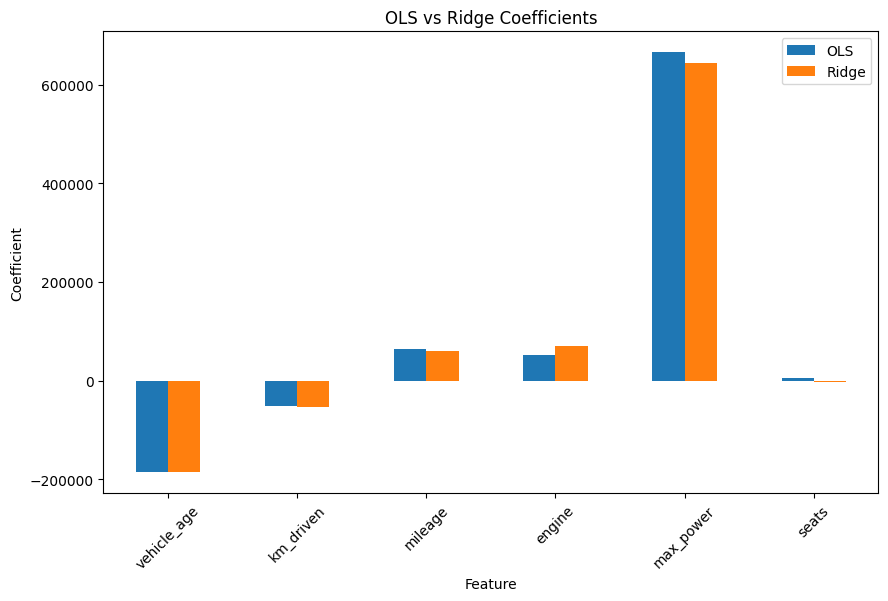

In [13]:
coef_comparison.set_index('Feature').plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("OLS vs Ridge Coefficients")
plt.ylabel("Coefficient")
plt.xticks(rotation=45)
plt.show()

In [14]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_ridge
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,190000,2.886361e+04
1,600000,5.760669e+05
2,665000,4.630482e+05
3,1570000,1.415544e+06
4,160000,-4.514885e+05
5,675000,1.123490e+06
6,465000,4.386318e+05
7,260000,3.882598e+05
8,300000,6.611088e+05
9,850000,1.735513e+06


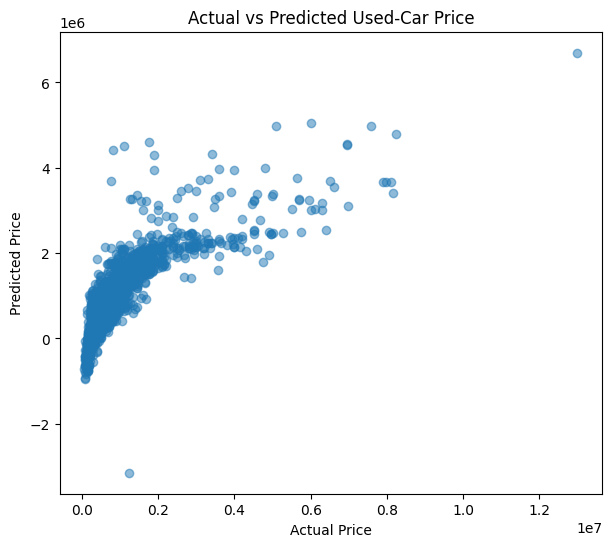

In [15]:
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.5
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Used-Car Price")

plt.show()